In [8]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import *
from plotnine import *
import scanpy as sc
import anndata as ad
from matplotlib.path import Path
import os
from scib.metrics import *
from sklearn.neighbors import NearestNeighbors
from pathlib import Path



In [2]:
# read in all csv files from datapath into 1D arrays

data_path = "/nfs/home/students/s.reif/SysMed/SysBioSDD/evaluation_metrics/examples"
dirs = os.listdir(data_path)
dict_all_methods = {}
adata = None

# for csvs in datapath make 1D array with array name of csvs

for csv_file in dirs:
    array_name = os.path.splitext(csv_file)[0]
    array_name_df = pd.read_csv(os.path.join(data_path, csv_file), header=None)
    globals()[array_name] = array_name_df.to_numpy().flatten()
    # adata.obs[array_name] = globals()[array_name]
    print(f"Loaded {array_name} from {csv_file}")
    if array_name != "groundtruth":
        dict_all_methods[array_name] = globals()[array_name]
    else:
        groundtruth = globals()[array_name]

print(f"Total arrays loaded: {len(dict_all_methods)}")
print("Arrays:", [os.path.splitext(csv_file)[0] for csv_file in dirs])
print(dict_all_methods)



Loaded ensemble from ensemble.csv
Loaded groundtruth from groundtruth.csv
Loaded bayesspace from bayesspace.csv
Loaded graphst from graphst.csv
Total arrays loaded: 3
Arrays: ['ensemble', 'groundtruth', 'bayesspace', 'graphst']
{'ensemble': array([1, 2, 1, 1, 1, 1, 2, 3, 3, 4, 4, 5, 5, 6, 6]), 'bayesspace': array([1, 2, 1, 1, 1, 1, 3, 4, 4, 4, 4, 5, 5, 5, 5]), 'graphst': array([1, 2, 1, 2, 2, 2, 2, 3, 4, 4, 4, 5, 5, 5, 6])}


# General Visualizations: UMAP and sankey plots

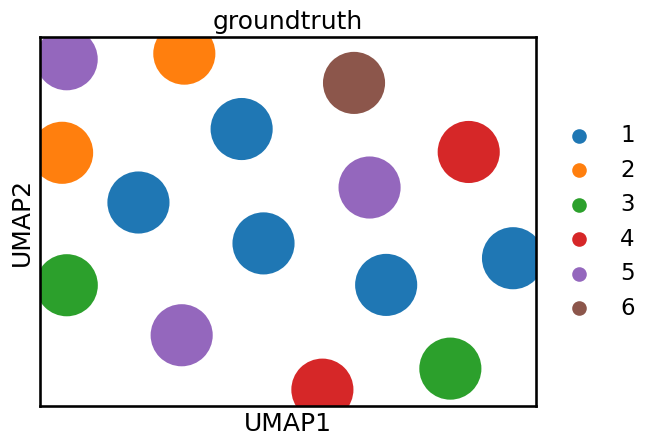

In [11]:
# general UMAP visualizations for all arrays

# Dummy data for UMAP
adata = ad.AnnData(X=np.random.rand(len(groundtruth), 10)) 

# path for umap plots
umap_path = "/nfs/home/students/s.reif/SysMed/SysBioSDD/evaluation_metrics/plots"
sc.settings.figdir = Path(umap_path)

if not os.path.exists(umap_path):
    os.makedirs(umap_path)

if groundtruth is not None:
        adata.obs['groundtruth'] = pd.Categorical(groundtruth)
        sc.pp.neighbors(adata)
        sc.tl.umap(adata)
        sc.pl.umap(adata, color='groundtruth', title='groundtruth', save = "_groundtruth.png")
        # save umap plot
        #plt.savefig(os.path.join(umap_path, "umap_groundtruth.png"))
        #plt.close() 
        
for method_name, values in dict_all_methods.items():
    adata.obs[method_name] = pd.Categorical(values)
    if 'X_umap' not in adata.obsm:
        sc.pp.neighbors(adata)
        sc.tl.umap(adata)
    sc.pl.umap(adata, color=method_name, title=method_name, show=False, save=f"_{method_name}.png")
    # save umap plot
    #plt.savefig(os.path.join(umap_path, f"umap_{method_name}.png"))
    #plt.close()

In [5]:
# sankey plots for all arrays compared to groundtruth

import plotly.graph_objects as go
import numpy as np
import pandas as pd

def plot_sankey_diagram(methods_dict, ground_truth=None, 
                        method_colors=None, title="Sankey Diagram of Clustering Methods"):
    """
    Create Sankey diagram showing relationships between clustering methods
    
    Parameters:
    -----------
    methods_dict : dict
        Dictionary with method names as keys and cluster labels as values
        Example: {'EnSDD': ensdd_labels, 'STAGATE': stagate_labels, 'SpaGCN': spagcn_labels}
    ground_truth : array-like, optional
        Ground truth labels (expert annotation)
    method_colors : dict, optional
        Dictionary mapping method names to colors
    title : str
        Title of the plot
    """
    
    # Add ground truth if provided
    if ground_truth is not None:
        methods_dict = {'Ground Truth': ground_truth, **methods_dict}
    
    # Prepare data
    method_names = list(methods_dict.keys())
    n_methods = len(method_names)
    n_spots = len(list(methods_dict.values())[0])
    
    # Create all node labels: "Method_Cluster#"
    node_labels = []
    node_methods = []  # Track which method each node belongs to
    node_indices = {}  # Map from (method, cluster) to node index
    
    current_index = 0
    for method_idx, method_name in enumerate(method_names):
        labels = methods_dict[method_name]
        unique_clusters = np.unique(labels)
        
        for cluster in unique_clusters:
            node_label = f"{method_name}: {cluster}"
            node_labels.append(node_label)
            node_methods.append(method_name)
            node_indices[(method_name, cluster)] = current_index
            current_index += 1
    
    n_nodes = len(node_labels)
    
    # Create links between consecutive methods
    source = []
    target = []
    value = []
    link_colors = []
    
    # Define default colors for methods
    if method_colors is None:
        # Use Plotly's categorical colors (without transparency)
        default_colors = [
            '#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd',
            '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf'
        ]
        method_colors = {method: default_colors[i % len(default_colors)] 
                        for i, method in enumerate(method_names)}
    
    # Create links between consecutive pairs of methods
    for i in range(n_methods - 1):
        method_a = method_names[i]
        method_b = method_names[i + 1]
        
        labels_a = methods_dict[method_a]
        labels_b = methods_dict[method_b]
        
        # Create contingency matrix
        unique_a = np.unique(labels_a)
        unique_b = np.unique(labels_b)
        
        for idx_a, cluster_a in enumerate(unique_a):
            for idx_b, cluster_b in enumerate(unique_b):
                # Count spots that are in cluster_a in method_a and cluster_b in method_b
                count = np.sum((labels_a == cluster_a) & (labels_b == cluster_b))
                
                if count > 0:  # Only add if there are spots
                    source_idx = node_indices[(method_a, cluster_a)]
                    target_idx = node_indices[(method_b, cluster_b)]
                    
                    source.append(source_idx)
                    target.append(target_idx)
                    value.append(count)
                    
                    # Color based on source method - WITHOUT TRANSPARENCY
                    link_colors.append(method_colors[method_a])
    
    # Create the Sankey diagram
    fig = go.Figure(data=[go.Sankey(
        node=dict(
            pad=15,
            thickness=20,
            line=dict(color="black", width=0.5),
            label=node_labels,
            color=[method_colors[method] for method in node_methods],
            hovertemplate='%{label}<br>Total spots: %{value}<extra></extra>'
        ),
        link=dict(
            source=source,
            target=target,
            value=value,
            color=link_colors,
            hovertemplate='From %{source.label}<br>To %{target.label}<br>Spots: %{value}<extra></extra>'
        )
    )])
    
    # Update layout
    fig.update_layout(
        #title_text=title,
        title_font_size=20,
        font_size=12,
        height=600,
        annotations=[
            dict(
                x=0.5,
                y=1.1,
                xref="paper",
                yref="paper",
                text=title,
                showarrow=False,
                font=dict(size=16)
            )
        ]
    )
    
    return fig

In [6]:
fig_sankey = plot_sankey_diagram(dict_all_methods, ground_truth=groundtruth,
                                 title="Sankey Diagram of Clustering Methods vs Ground Truth")

fig_sankey.show()
fig_sankey.write_image(os.path.join(umap_path, "sankey_diagram.png"))

/nfs/home/students/s.reif/.local/lib/python3.10/site-packages/plotly/io/_kaleido.py:528: DeprecationWarning:


Support for the 'engine' argument is deprecated and will be removed after September 2025.
Kaleido will be the only supported engine at that time.




# Accuracy metrics

## ARI score
- adjusted rand score: measures similarity between two clusterings by considering all pairs of samples and counting pairs that are assigned in the same or different clusters in the predicted and true clusterings.
- ARI = (RI - Expected_RI) / (max(RI) - Expected_RI)
- where RI is the Rand Index, which measures the percentage of correct decisions made regarding whether pairs of samples are in the same or different clusters.
- The ARI ranges from -1 to 1, where 1 indicates perfect agreement between the two clusterings, 0 indicates random clustering, and negative values indicate less agreement than expected by chance.

### usage:
- adjusted_rand_score(true_labels, predicted_labels): needs array of true labels and array of predicted labels as input

WITH GROUNDTRUTH!

- calculate each method with groundtruth
- calculate ensemble with groundtruth
- compare resultss with t-tests? p-values?

## Purity score
- Purity: measures the extent to which clusters contain a single class of data points.
- Purity = (1/N) * Σ max_j |C_i ∩ L_j
- where N is the total number of data points, C_i is the set of data points in cluster i, and L_j is the set of data points in class j.
- so: Purity = (sum of spots in dominant expert class for each cluster) / (total spots)
- The Purity score ranges from 0 to 1, where 1 indicates that each cluster contains only data points from a single class, and 0 indicates that clusters are completely mixed with data points from different classes.

### usage:
- calculate contingency matrix (confusion matrix) between true labels and predicted labels
- Purity = sum of max values in each column of contingency matrix / total number of samples

WITH GROUNDTRUTH!

## AMI score
- adjusted mutual information: measures the agreement between two clusterings by considering the mutual information between the true and predicted clusterings, adjusted for random chance.
- AMI = (MI - Expected_MI) / (max(H(true), H(predicted)) - Expected_MI)
- where MI is the mutual information between the true and predicted clusterings, and H is the entropy of the clusterings.
- The AMI ranges from 0 to 1, where 1 indicates perfect agreement between the two clusterings, and 0 indicates random clustering.

### usage:
- adjusted_mutual_info_score(true_labels, predicted_labels): needs array of true labels and array of predicted labels as input

WITH GROUNDTRUTH!


In [7]:
def purity_score(y_true, y_pred):
    # compute contingency matrix (also called confusion matrix)
    contingency_matrix = pd.crosstab(y_true, y_pred)
    return np.sum(np.amax(contingency_matrix.values, axis=0)) / np.sum(contingency_matrix.values)

In [8]:
# see if groundtruth exists: else accuracy skipped

if 'groundtruth' in globals():
    
    # calculate ARI and AMI for each method in dict_all_methods
    ARI_scores = {}
    Purity_scores = {}
    AMI_scores = {}
    for method_name, values in dict_all_methods.items():
        ARI = adjusted_rand_score(groundtruth, values)
        Purity = purity_score(groundtruth, values)
        AMI = adjusted_mutual_info_score(groundtruth, values)
        ARI_scores[method_name] = ARI
        Purity_scores[method_name] = Purity
        AMI_scores[method_name] = AMI
    
    print(ARI_scores)
    print(Purity_scores)
    print(AMI_scores)
else:
    print("Groundtruth labels not found. Skipping accuracy metrics calculation.")   

{'ensemble': 0.8864864864864865, 'bayesspace': 0.7443700547778455, 'graphst': 0.4608010955152345}
{'ensemble': 0.9333333333333333, 'bayesspace': 0.8, 'graphst': 0.8}
{'ensemble': 0.8656735178857443, 'bayesspace': 0.7541100879193057, 'graphst': 0.596069610501359}


## statistical tests
- only if we have multiple datasets with groundtruth
- t-test to compare means of two methods across multiple datasets

- possibly also multiple testing correction (e.g., Bonferroni correction)

# Spatial coherence metrics

## LISI score
- Local Inverse Simpson's Index (LISI): measures the diversity of clusters within a local neighborhood of each cell: local diversity of cluster labels.
- LISI = 1 / Σ (p_i^2)
- where p_i is the proportion of cluster i within the local neighborhood.
- The LISI score ranges from 1 to the number of clusters, where higher values indicate greater diversity of clusters within the local neighborhood.

### usage:


## PAS: Percentage of Abnormal Spots
- PAS measures the proportion of spots in a spatial transcriptomics dataset that are classified as "abnormal" based on their gene expression profiles.
- PAS = (Number of Abnormal Spots / Total Number of Spots) * 100
- A higher PAS indicates a greater prevalence of abnormal spots, which may suggest issues with data quality or biological variability.

### usage:
- calculate abnormal spots based on some criteria (e.g., expression thresholds, clustering results)
- calculate total number of spots
- pas_score = (num_abnormal_spots / total_spots) * 100

In [ ]:
def calculate_pas(spatial_coords, labels, k=10, threshold=0.6):
    n_spots = len(labels)
    
    # Find k nearest neighbors (including self)
    nn = NearestNeighbors(n_neighbors=k+1)
    nn.fit(spatial_coords)
    distances, indices = nn.kneighbors(spatial_coords)
    
    # Remove self from neighbors (first column)
    neighbor_indices = indices[:, 1:]
    ambiguous_count = 0
    
    for i in range(n_spots):
        # Get labels of k nearest neighbors
        neighbor_labels = labels[neighbor_indices[i]]
        current_label = labels[i]
        
        # Count neighbors with different label
        different_count = np.sum(neighbor_labels != current_label)
        
        # Check if ambiguous (≥60% different)
        if different_count >= k * threshold:
            ambiguous_count += 1
    
    return ambiguous_count / n_spots

In [ ]:
ilisi_scores = {}
pas_scores = {}

# need to use spatial coordinates for spatial data
# assume it is saved in adata.obsm['spatial']

for method in dict_all_methods.keys():
    adata_temp = adata.copy()

# create knn graph based on spatial coordinates
    sc.pp.neighbors(adata_temp, use_rep='spatial', n_neighbors=90)
    
    ilisi_score = ilisi_graph(
        adata_temp,
        batch_key=method,  # Using method labels as "batches"
        type_='knn',     # Using nearest neighbor graph
        k0=90,            # Number of nearest neighbors
        scale=True        # Scale between 0 and 1
    )
    
    pas_score = calculate_pas(
        adata_temp.obsm['spatial'], 
        dict_all_methods[method], 
        k=10, 
        threshold=0.6)
    
    ilisi_scores[method] = ilisi_score
    pas_scores[method] = pas_score
    
    print(f"{method} iLISI score: {ilisi_score}")
    print(f"{method} PAS score: {pas_score}")

# intra-cluster quality metrics

## Silhouette score
- Silhouette score: measures how similar a spot is to its own cluster compared to other clusters
- Silhouette = (b - a) / max(a, b)
- where a is the average distance between a spot and all other spots in the same cluster, and b is the average distance between a spot and all other spots in the nearest cluster.
- The Silhouette score ranges from -1 to 1, where 1 indicates that spots are well clustered, 0 indicates overlapping clusters, and negative values indicate that spots may have been assigned to the wrong cluster.

### usage:
- silhouette_score(data, labels): needs data matrix and array of cluster labels as input


### 2 Methods: 
- calculate sc in adata.X: transcriptome space
- calculate sc in spatial space: adata.obsm['spatial']
- possibly average both scores for final silhouette score???

In [ ]:
# for transcriptome-based silhouette score

# Method 1: Using the raw expression data (adata.X)
# calculates in expression space, higher = better separation
def calculate_silhouette_expression(adata, method_name):
    labels = adata.obs[method_name].values
    
    # Use PCA embeddings for faster computation
    if 'X_pca' in adata.obsm:
        X = adata.obsm['X_pca'][:, :50]
    else:
        # Use raw expression
        X = adata.X.toarray() if hasattr(adata.X, 'toarray') else adata.X
    
    score = silhouette_score(
        X, 
        labels, 
        metric='euclidean',
        #sample_size=min(1000, len(labels))  # Subsample for speed
    )
    return score


In [ ]:
# for physical space-based silhouette score
def calculate_silhouette_physical(adata, method_name):
    labels = adata.obs[method_name].values
    spatial_coords = adata.obsm['spatial']
    
    score = silhouette_score(
        spatial_coords, 
        labels, 
        metric='euclidean',
        #sample_size=min(1000, len(labels))  # Subsample for speed
    )
    return score

In [ ]:
# calculate silhouette scores for each method
silhouette_expression_scores = {}   
silhouette_physical_scores = {}

for method in dict_all_methods.keys():
    expr_score = calculate_silhouette_expression(adata, method)
    phys_score = calculate_silhouette_physical(adata, method)
    
    silhouette_expression_scores[method] = expr_score
    silhouette_physical_scores[method] = phys_score
    
    print(f"{method} Silhouette Expression score: {expr_score}")
    print(f"{method} Silhouette Physical score: {phys_score}")